# Final Full-Pipeline Benchmark & Verification (Colab)

Notebook tích hợp toàn bộ **Pipeline Người A (YOLO26 + ByteTrack/BoT-SORT)** và **Động cơ Hình học BEV & Phân tích Không gian của Người B** để kiểm chứng thực tế trên 2 bộ dữ liệu:
1. **BrnoCompSpeed:** Kiểm chứng độ chính xác thuần túy của động cơ đo tốc độ BEV bằng cách so sánh:
   - `yolo26s.pt` (pretrained COCO, lọc giữ 3 lớp `car`, `bus`, `truck`) $\rightarrow$ cô lập sai số detection.
   - `yolo26_vn_finetuned.pt` (trọng số Người A train 2 giai đoạn) $\rightarrow$ đánh giá hiệu năng thực tế của mô hình nhóm.
2. **CCTV Giao thông Đà Nẵng (`nhthau/CCTV-giao-thong-da-nang`):** Tải 3 video thực tế bằng Colab Secret tên `HuggingFace` và chạy Full-Pipeline (Tách nền $\rightarrow$ Dò vạch $\rightarrow$ BEV $\rightarrow$ Tốc độ, Đếm xe, Sai làn, THW, Heatmap).

> **Quy ước đặt tên trọng số:** Khi Người A train xong, bạn lưu/đổi tên file `best.pt` thành **`yolo26_vn_finetuned.pt`** và đặt vào `/content/yolo26_vn_finetuned.pt` (hoặc giữ nguyên đường dẫn mặc định `/content/traffic_bev_a/runs/yolo26_stage2_finetune/weights/best.pt`, notebook sẽ tự động tìm thấy).


In [1]:
# === [0] Cài đặt các thư viện còn thiếu trên Google Colab ===
!pip -q install ultralytics lap "huggingface_hub<2.0" kagglehub gdown

In [2]:
# === [1] Thiết lập môi trường, GPU & Đường dẫn ===
import os
import json
import math
import time
import shutil
import zipfile
import urllib.request
from pathlib import Path
from collections import defaultdict, deque

import cv2
import yaml
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.unicode_minus"] = False

WORK_DIR = Path("/content/final_pipeline")
WEIGHTS_DIR = WORK_DIR / "weights"
BRNO_DIR = WORK_DIR / "brnocompspeed"
DANANG_DIR = WORK_DIR / "danang_cctv"
OUT_DIR = WORK_DIR / "outputs"

for d in [WORK_DIR, WEIGHTS_DIR, BRNO_DIR, DANANG_DIR, OUT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

DEVICE = "0" if torch.cuda.is_available() else "cpu"

def get_gpu_profile():
    if not torch.cuda.is_available():
        return {"name": "CPU", "vram_gb": 0.0, "half": False, "imgsz": 640, "vid_stride": 2}
    props = torch.cuda.get_device_properties(0)
    vram_gb = props.total_memory / (1024 ** 3)
    torch.backends.cudnn.benchmark = True
    if vram_gb >= 35:  # A100 / H100
        return {"name": props.name, "vram_gb": vram_gb, "half": True, "imgsz": 640, "vid_stride": 1}
    elif vram_gb >= 20:  # L4 / RTX 3090 / 4090
        return {"name": props.name, "vram_gb": vram_gb, "half": True, "imgsz": 640, "vid_stride": 1}
    else:  # T4 (15 GB) hoặc GPU nhỏ hơn
        return {"name": props.name, "vram_gb": vram_gb, "half": True, "imgsz": 640, "vid_stride": 1}

GPU_PROF = get_gpu_profile()
print(f"Device: {DEVICE} | GPU: {GPU_PROF['name']} ({GPU_PROF['vram_gb']:.1f} GB) | FP16={GPU_PROF['half']} | imgsz={GPU_PROF['imgsz']}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Device: 0 | GPU: NVIDIA L4 (22.0 GB) | FP16=True | imgsz=640


## Bước 1: Nạp Trọng số Mô hình (COCO `yolo26s.pt` & Trọng số Người A `yolo26_vn_finetuned.pt`)
- `yolo26s.pt`: Tự tải từ Ultralytics, lọc giữ 3 lớp chuẩn COCO: `2: car`, `5: bus`, `7: truck`.
- `yolo26_vn_finetuned.pt`: Tự động tìm tại `/content/yolo26_vn_finetuned.pt`, `/content/final_pipeline/weights/yolo26_vn_finetuned.pt`, Google Drive, hoặc đường dẫn output mặc định của Người A (`/content/traffic_bev_a/runs/yolo26_stage2_finetune/weights/best.pt`).


In [3]:
# === [2] Nạp 2 mô hình: Pretrained COCO & Fine-tuned Người A ===
COCO_MODEL_NAME = "yolo26s.pt"
COCO_TARGET_CLASSES = [2, 5, 7]  # 2: car, 5: bus, 7: truck
COCO_ID_TO_CANONICAL = {
    2: (1, "car"),
    5: (2, "bus"),
    7: (3, "truck"),
}

VN_CANDIDATES = [
    Path("/content/yolo26_vn_finetuned.pt"),
    WEIGHTS_DIR / "yolo26_vn_finetuned.pt",
    Path("/content/drive/MyDrive/yolo26_vn_finetuned.pt"),
    Path("/content/traffic_bev_a/runs/yolo26_stage2_finetune/weights/best.pt"),
    Path("/content/traffic_bev_a/runs/yolo26_stage1/weights/best.pt"),
]

VN_WEIGHTS_PATH = next((p for p in VN_CANDIDATES if p.exists()), None)
print(f"Đang nạp COCO model: {COCO_MODEL_NAME} ...")
model_coco = YOLO(COCO_MODEL_NAME)

if VN_WEIGHTS_PATH is not None:
    print(f"Đã tìm thấy trọng số Người A tại: {VN_WEIGHTS_PATH}")
    model_vn = YOLO(str(VN_WEIGHTS_PATH))
else:
    print("[CẢNH BÁO] Chưa tìm thấy yolo26_vn_finetuned.pt!")
    print("Vui lòng upload hoặc đổi tên file best.pt thành /content/yolo26_vn_finetuned.pt rồi chạy lại cell này.")
    model_vn = None

Đang nạp COCO model: yolo26s.pt ...
Đã tìm thấy trọng số Người A tại: /content/yolo26_vn_finetuned.pt


## Bước 2: Đóng gói Động cơ Hình học & Phân tích Không gian BEV (Người B) + Trình chạy Tracking (Người A)
Toàn bộ các thuật toán từ Notebook của Người B được đóng gói thành hàm/class chuẩn:
- **Phần 2:** `compute_temporal_median_bg`, `undistort_and_clahe`
- **Phần 3:** `detect_lanes_hls_canny_hough`, `calibrate_homography_from_trapezoid`
- **Phần 4:** `KalmanFilter2D`, `point_in_polygon_ray_casting`, `segments_intersect`, `BEVSpatialAnalyticsEngine` (Sliding Window + EMA + Kalman, Đếm xe qua vạch ảo, Sai làn có Safety Margin + Debouncing, Time Headway THW, Congestion Heatmap chiếu ngược $H^{-1}$).


In [4]:
# === [3] Động cơ Hình học BEV & Tracking Full-Pipeline ===
CANONICAL_NAMES = {0: "motorbike", 1: "car", 2: "bus", 3: "truck"}
VEH_LENGTH_M = {"motorbike": 2.0, "car": 4.5, "bus": 10.5, "truck": 7.5}

def is_valid_video(video_path: Path) -> bool:
    if not video_path.exists() or not video_path.is_file() or video_path.stat().st_size < 50_000:
        return False
    cap = cv2.VideoCapture(str(video_path))
    ok = cap.isOpened() and int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) > 5 and int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) > 0
    cap.release()
    return ok

def clean_invalid_videos(folder: Path):
    for p in list(folder.rglob("*.mp4")) + list(folder.rglob("*.avi")):
        if not is_valid_video(p):
            print(f"  [Auto-Clean] Xóa file video lỗi/HTML giả: {p.name}")
            p.unlink(missing_ok=True)
    return sorted([p for p in (list(folder.rglob("*.mp4")) + list(folder.rglob("*.avi"))) if is_valid_video(p)])

def compute_temporal_median_bg(video_path: Path, num_samples: int = 80):
    cap = cv2.VideoCapture(str(video_path))
    assert cap.isOpened(), f"Không mở được video: {video_path}"
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(cap.get(cv2.CAP_PROP_FPS)) or 30.0
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    indices = set(np.linspace(0, max(0, total - 1), min(num_samples, max(1, total)), dtype=int).tolist())
    frames = []
    sample_crowded = None
    idx = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if idx == min(15, max(0, total - 1)):
            sample_crowded = frame.copy()
        if idx in indices:
            frames.append(frame)
        idx += 1
    cap.release()
    bg_median = np.median(np.stack(frames, axis=0), axis=0).astype(np.uint8)
    return sample_crowded, bg_median, {"width": w, "height": h, "fps": fps, "frame_count": idx}

def undistort_and_clahe(img_bgr: np.ndarray, k1: float = -0.02, k2: float = 0.005):
    h, w = img_bgr.shape[:2]
    fx = fy = max(w, h) * 1.15
    cx, cy = w / 2.0, h / 2.0
    K = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]], dtype=np.float64)
    D = np.array([k1, k2, 0.0, 0.0, 0.0], dtype=np.float64)
    undistorted = cv2.undistort(img_bgr, K, D, None, K)
    hls = cv2.cvtColor(undistorted, cv2.COLOR_BGR2HLS)
    h_ch, l_ch, s_ch = cv2.split(hls)
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    l_eq = clahe.apply(l_ch)
    enhanced_bgr = cv2.cvtColor(cv2.merge([h_ch, l_eq, s_ch]), cv2.COLOR_HLS2BGR)
    return undistorted, enhanced_bgr

def detect_lanes_hls_canny_hough(img_bgr: np.ndarray, roi_poly: np.ndarray):
    hls = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HLS)
    white_mask = cv2.inRange(hls, np.array([0, 175, 0]), np.array([180, 255, 110]))
    yellow_mask = cv2.inRange(hls, np.array([12, 85, 75]), np.array([38, 255, 255]))
    color_mask = cv2.bitwise_or(white_mask, yellow_mask)
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    masked_gray = cv2.bitwise_and(gray, gray, mask=color_mask)
    edges = cv2.Canny(cv2.GaussianBlur(masked_gray, (5, 5), 0), 50, 150)
    roi_mask = np.zeros_like(edges)
    cv2.fillPoly(roi_mask, [roi_poly.astype(np.int32)], 255)
    edges_roi = cv2.bitwise_and(edges, roi_mask)
    lines = cv2.HoughLinesP(edges_roi, rho=1, theta=np.pi / 180, threshold=25, minLineLength=25, maxLineGap=20)
    return color_mask, edges_roi, lines

def build_bev_calibration(vid_w: int, vid_h: int, lane_width_m: float = 3.5, road_len_m: float = 35.0,
                          scale_px_per_m: float = 20.0, src_trapezoid_norm=None):
    if src_trapezoid_norm is None:
        # Khung hình thang mặc định cho CCTV giao thông nhìn chéo từ trên cao
        src_trapezoid_norm = [[0.36, 0.28], [0.64, 0.28], [0.92, 0.96], [0.08, 0.96]]
    src_uv = np.array([[x * vid_w, y * vid_h] for x, y in src_trapezoid_norm], dtype=np.float64)
    x_start = 2.0
    x_l1, x_l2, x_l3 = x_start + lane_width_m, x_start + 2 * lane_width_m, x_start + 3 * lane_width_m
    y_top, y_bot = 2.0, 2.0 + road_len_m
    dst_m = np.array([[x_start, y_top], [x_l3, y_top], [x_l3, y_bot], [x_start, y_bot]], dtype=np.float64)

    H_m, _ = cv2.findHomography(src_uv, dst_m, cv2.RANSAC, ransacReprojThreshold=3.0 / scale_px_per_m)
    H_px, _ = cv2.findHomography(src_uv, dst_m * scale_px_per_m, cv2.RANSAC, ransacReprojThreshold=3.0)
    H_inv_px = np.linalg.inv(H_px)

    bev_w_m = x_l3 + 2.0
    bev_h_m = y_bot + 2.0
    bev_img_w = int(round(bev_w_m * scale_px_per_m))
    bev_img_h = int(round(bev_h_m * scale_px_per_m))

    lanes_cfg = {
        "lane_1": {
            "polygon_m": [[x_start, y_top], [x_l1, y_top], [x_l1, y_bot], [x_start, y_bot]],
            "allowed_classes": ["car", "bus", "truck"],
            "tripwire_m": [[x_start, y_top + 0.35 * road_len_m], [x_l1, y_top + 0.35 * road_len_m]],
            "direction": [0.0, 1.0],
        },
        "lane_2": {
            "polygon_m": [[x_l1, y_top], [x_l2, y_top], [x_l2, y_bot], [x_l1, y_bot]],
            "allowed_classes": ["motorbike", "car", "bus", "truck"],
            "tripwire_m": [[x_l1, y_top + 0.45 * road_len_m], [x_l2, y_top + 0.45 * road_len_m]],
            "direction": [0.0, 1.0],
        },
        "lane_3": {
            "polygon_m": [[x_l2, y_top], [x_l3, y_top], [x_l3, y_bot], [x_l2, y_bot]],
            "allowed_classes": ["motorbike", "car"],
            "tripwire_m": [[x_l2, y_top + 0.35 * road_len_m], [x_l3, y_top + 0.35 * road_len_m]],
            "direction": [0.0, -1.0],
        },
    }
    return {
        "H_m": H_m, "H_px": H_px, "H_inv_px": H_inv_px,
        "scale_px_per_m": scale_px_per_m,
        "bev_img_w": bev_img_w, "bev_img_h": bev_img_h,
        "reliable_zone_uv": src_uv.astype(np.float32),
        "lanes": lanes_cfg,
    }

class KalmanFilter2D:
    def __init__(self, dt=1.0 / 30.0):
        self.kf = cv2.KalmanFilter(4, 2)
        self.kf.transitionMatrix = np.array(
            [[1, 0, dt, 0], [0, 1, 0, dt], [0, 0, 1, 0], [0, 0, 0, 1]], dtype=np.float32
        )
        self.kf.measurementMatrix = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], dtype=np.float32)
        self.kf.processNoiseCov = np.diag([0.05, 0.05, 0.8, 0.8]).astype(np.float32)
        self.kf.measurementNoiseCov = np.eye(2, dtype=np.float32) * 0.08
        self.initialized = False

    def update(self, x_m: float, y_m: float):
        meas = np.array([[np.float32(x_m)], [np.float32(y_m)]])
        if not self.initialized:
            self.kf.statePost = np.array([[np.float32(x_m)], [np.float32(y_m)], [0.0], [0.0]], dtype=np.float32)
            self.initialized = True
        self.kf.predict()
        est = self.kf.correct(meas)
        return float(est[0, 0]), float(est[1, 0]), math.hypot(float(est[2, 0]), float(est[3, 0])) * 3.6

def point_in_polygon_ray_casting(x: float, y: float, poly: list) -> bool:
    inside = False
    n = len(poly)
    p1x, p1y = poly[0]
    for i in range(n + 1):
        p2x, p2y = poly[i % n]
        if y > min(p1y, p2y) and y <= max(p1y, p2y) and x <= max(p1x, p2x):
            if p1y != p2y:
                xints = (y - p1y) * (p2x - p1x) / (p2y - p1y) + p1x
            if p1x == p2x or x <= xints:
                inside = not inside
        p1x, p1y = p2x, p2y
    return inside

def shrink_rect_polygon(poly_m: list, margin_m: float = 0.30) -> list:
    xs = [p[0] for p in poly_m]
    ys = [p[1] for p in poly_m]
    return [
        [min(xs) + margin_m, min(ys) + margin_m], [max(xs) - margin_m, min(ys) + margin_m],
        [max(xs) - margin_m, max(ys) - margin_m], [min(xs) + margin_m, max(ys) - margin_m],
    ]

def cross_2d(o, a, b) -> float:
    return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])

def segments_intersect(p1, p2, q1, q2) -> bool:
    d1, d2 = cross_2d(q1, q2, p1), cross_2d(q1, q2, p2)
    d3, d4 = cross_2d(p1, p2, q1), cross_2d(p1, p2, q2)
    return (d1 * d2 <= 0) and (d3 * d4 <= 0) and (abs(d1) + abs(d2) > 1e-6)

def run_tracker_on_video(model: YOLO, video_path: Path, cam_id: str, is_coco: bool = False, max_frames: int = 450):
    cap = cv2.VideoCapture(str(video_path))
    fps = float(cap.get(cv2.CAP_PROP_FPS)) or 30.0
    cap.release()
    # Reset tracker state trước mỗi video mới để không bị lẫn track_id từ video trước
    model.predictor = None
    classes_arg = COCO_TARGET_CLASSES if is_coco else None
    stride = GPU_PROF["vid_stride"]
    results = model.track(
        source=str(video_path),
        tracker="bytetrack.yaml",
        persist=True,
        classes=classes_arg,
        conf=0.25,
        iou=0.5,
        imgsz=GPU_PROF["imgsz"],
        vid_stride=stride,
        device=DEVICE,
        stream=True,
        verbose=False,
    )
    records = []
    for fid, res in enumerate(results):
        if max_frames and fid >= max_frames:
            break
        if res.boxes is None or res.boxes.id is None:
            continue
        boxes = res.boxes.xyxy.cpu().numpy()
        ids = res.boxes.id.int().cpu().tolist()
        clss = res.boxes.cls.int().cpu().tolist()
        confs = res.boxes.conf.cpu().tolist()
        real_fid = fid * stride
        for box, tid, cid_raw, conf in zip(boxes, ids, clss, confs):
            if is_coco:
                if cid_raw not in COCO_ID_TO_CANONICAL:
                    continue
                cid, cname = COCO_ID_TO_CANONICAL[cid_raw]
            else:
                cid = int(cid_raw)
                cname = CANONICAL_NAMES.get(cid, "car")
            x1, y1, x2, y2 = [float(v) for v in box]
            records.append({
                "camera_id": cam_id,
                "frame_id": real_fid,
                "timestamp_ms": round(real_fid * (1000.0 / fps), 3),
                "fps": fps,
                "track_id": int(tid),
                "class_id": cid,
                "class_name": cname,
                "conf": float(conf),
                "bbox_xyxy": [round(x1, 2), round(y1, 2), round(x2, 2), round(y2, 2)],
                "footpoint_uv": [round((x1 + x2) / 2.0, 2), round(y2, 2)],
            })
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return records, fps

def run_bev_analytics(records: list, cfg: dict, fps: float):
    H_m = cfg["H_m"]
    scale = cfg["scale_px_per_m"]
    reliable_poly = cfg["reliable_zone_uv"]
    window_size = max(4, int(round(0.8 * fps)))
    debounce_frames = max(6, int(round(0.8 * fps)))
    ema_alpha = 0.30

    lanes_shrunk = {lid: shrink_rect_polygon(linfo["polygon_m"], 0.30) for lid, linfo in cfg["lanes"].items()}
    frames_dict = defaultdict(list)
    for r in records:
        frames_dict[r["frame_id"]].append(r)

    track_history = defaultdict(lambda: deque(maxlen=window_size))
    track_ema_speed = {}
    track_kalman = {}
    counted_ids = set()
    lane_counts = {lid: defaultdict(int) for lid in cfg["lanes"]}
    violation_streak = defaultdict(int)
    violated_ids = set()
    thw_alerts = 0
    heatmap_grid = np.zeros((cfg["bev_img_h"], cfg["bev_img_w"]), dtype=np.float32)
    speed_logs = []
    per_frame_objs = defaultdict(list)

    max_fid = max(frames_dict.keys()) if frames_dict else 0
    for fid in range(max_fid + 1):
        recs = frames_dict.get(fid, [])
        active_in_lanes = defaultdict(list)
        for r in recs:
            u, v = r["footpoint_uv"]
            if cv2.pointPolygonTest(reliable_poly, (float(u), float(v)), False) < 0:
                continue
            pt_m = cv2.perspectiveTransform(np.array([[[u, v]]], dtype=np.float64), H_m)[0, 0]
            xm, ym = float(pt_m[0]), float(pt_m[1])
            tid = r["track_id"]
            ts_s = r["timestamp_ms"] / 1000.0

            hist = track_history[tid]
            raw_kmh = 0.0
            if len(hist) >= 1:
                px, py, pts = hist[-1]
                raw_kmh = (math.hypot(xm - px, ym - py) / max(1e-4, ts_s - pts)) * 3.6
            hist.append((xm, ym, ts_s))

            win_kmh = raw_kmh
            vx_dir, vy_dir = 0.0, 0.0
            if len(hist) >= 2:
                x0, y0, t0_s = hist[0]
                dx, dy = xm - x0, ym - y0
                win_kmh = (math.hypot(dx, dy) / max(1e-4, ts_s - t0_s)) * 3.6
                nv = math.hypot(dx, dy)
                if nv > 1e-4:
                    vx_dir, vy_dir = dx / nv, dy / nv

            ema_kmh = ema_alpha * win_kmh + (1.0 - ema_alpha) * track_ema_speed.get(tid, win_kmh)
            track_ema_speed[tid] = ema_kmh
            if tid not in track_kalman:
                track_kalman[tid] = KalmanFilter2D(dt=1.0 / fps)
            _, _, kf_kmh = track_kalman[tid].update(xm, ym)

            if len(hist) >= 3 and 0.5 <= ema_kmh <= 160.0:
                speed_logs.append({
                    "frame_id": fid, "track_id": tid, "class_name": r["class_name"],
                    "xm": xm, "ym": ym, "raw_kmh": raw_kmh, "ema_kmh": ema_kmh, "kf_kmh": kf_kmh
                })

            # Đếm lưu lượng qua vạch ảo
            if len(hist) >= 2 and tid not in counted_ids:
                prev_pt, curr_pt = (hist[-2][0], hist[-2][1]), (xm, ym)
                for lid, linfo in cfg["lanes"].items():
                    tw1, tw2 = linfo["tripwire_m"]
                    if segments_intersect(prev_pt, curr_pt, tw1, tw2):
                        counted_ids.add(tid)
                        lane_counts[lid][r["class_name"]] += 1
                        break

            # Bắt lỗi đi sai làn
            assigned_lane = None
            for lid, linfo in cfg["lanes"].items():
                if point_in_polygon_ray_casting(xm, ym, linfo["polygon_m"]):
                    assigned_lane = lid
                    active_in_lanes[lid].append((tid, r["class_name"], xm, ym, ema_kmh))
                    if r["class_name"] not in linfo["allowed_classes"]:
                        if point_in_polygon_ray_casting(xm, ym, lanes_shrunk[lid]):
                            violation_streak[tid] += 1
                            if violation_streak[tid] >= debounce_frames:
                                violated_ids.add(tid)
                        else:
                            violation_streak[tid] = 0
                    else:
                        violation_streak[tid] = 0
                    break
            if assigned_lane is None:
                violation_streak[tid] = 0

            # Bản đồ nhiệt ùn tắc (v < 10 km/h)
            if ema_kmh < 10.0:
                gx, gy = int(round(xm * scale)), int(round(ym * scale))
                if 0 <= gx < cfg["bev_img_w"] and 0 <= gy < cfg["bev_img_h"]:
                    cv2.circle(heatmap_grid, (gx, gy), int(round(0.8 * scale)), 1.0 / max(ema_kmh, 1.0), -1)

            per_frame_objs[fid].append({
                "tid": tid,
                "class_name": r["class_name"],
                "bbox_xyxy": r["bbox_xyxy"],
                "xm": xm,
                "ym": ym,
                "ema_kmh": ema_kmh,
                "is_violation": tid in violated_ids,
            })

        # Cảnh báo bám sát nguy hiểm (THW < 1.8s khi v > 20 km/h)
        for lid, objs in active_in_lanes.items():
            if len(objs) < 2:
                continue
            objs_sorted = sorted(objs, key=lambda o: o[3])
            for i in range(len(objs_sorted) - 1):
                _, c_lead, _, y_lead, _ = objs_sorted[i + 1]
                _, c_rear, _, y_rear, v_rear_kmh = objs_sorted[i]
                if v_rear_kmh > 20.0:
                    gap_m = max(0.0, (y_lead - y_rear) - 0.5 * (VEH_LENGTH_M[c_lead] + VEH_LENGTH_M[c_rear]))
                    thw = gap_m / (v_rear_kmh / 3.6)
                    if thw < 1.8:
                        thw_alerts += 1

    speed_df = pd.DataFrame(speed_logs)
    return {
        "speed_df": speed_df,
        "total_counted": len(counted_ids),
        "lane_counts": {lid: dict(c) for lid, c in lane_counts.items()},
        "lane_violations": len(violated_ids),
        "thw_alerts": thw_alerts,
        "heatmap_bev": cv2.GaussianBlur(heatmap_grid, (31, 31), 0),
        "per_frame_objs": per_frame_objs,
    }

def render_camera_and_bev_videos(video_path: Path, cfg: dict, res_analytics: dict, out_dir: Path, cam_id: str, max_frames: int = 450):
    cap = cv2.VideoCapture(str(video_path))
    fps = float(cap.get(cv2.CAP_PROP_FPS)) or 30.0
    vid_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    vid_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    bev_w, bev_h = cfg["bev_img_w"], cfg["bev_img_h"]
    scale = cfg["scale_px_per_m"]

    det_out_path = out_dir / f"{cam_id}_detected.mp4"
    bev_out_path = out_dir / f"{cam_id}_bev.mp4"
    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    w_det = cv2.VideoWriter(str(det_out_path), fourcc, fps, (vid_w, vid_h))
    w_bev = cv2.VideoWriter(str(bev_out_path), fourcc, fps, (bev_w, bev_h))

    per_frame_objs = res_analytics["per_frame_objs"]
    hm = res_analytics["heatmap_bev"]
    hm_norm = np.uint8(255 * hm / max(1e-6, float(hm.max())))
    hm_color = cv2.applyColorMap(hm_norm, cv2.COLORMAP_JET)

    fid = 0
    while fid < max_frames:
        ret, frame = cap.read()
        if not ret:
            break
        det_frame = frame.copy()
        cv2.polylines(det_frame, [cfg["reliable_zone_uv"].astype(np.int32)], True, (0, 255, 255), 2)

        bev_frame = cv2.warpPerspective(frame, cfg["H_px"], (bev_w, bev_h))
        bev_frame = cv2.addWeighted(bev_frame, 0.78, hm_color, 0.22, 0)
        for linfo in cfg["lanes"].values():
            tw = (np.array(linfo["tripwire_m"]) * scale).astype(np.int32)
            cv2.line(bev_frame, tuple(tw[0]), tuple(tw[1]), (255, 0, 255), 2)

        for obj in per_frame_objs.get(fid, []):
            x1, y1, x2, y2 = [int(v) for v in obj["bbox_xyxy"]]
            color = (0, 0, 255) if obj["is_violation"] else (0, 255, 0)
            cv2.rectangle(det_frame, (x1, y1), (x2, y2), color, 2)
            label = f"#{obj['tid']} {obj['class_name']} {obj['ema_kmh']:.1f}km/h"
            cv2.putText(det_frame, label, (x1, max(18, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.52, color, 2)

            bx, by = int(round(obj["xm"] * scale)), int(round(obj["ym"] * scale))
            if 0 <= bx < bev_w and 0 <= by < bev_h:
                cv2.circle(bev_frame, (bx, by), 6, color, -1)
                cv2.putText(bev_frame, f"#{obj['tid']} {obj['ema_kmh']:.0f}", (bx + 6, by), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 255), 1)

        cv2.putText(det_frame, f"{cam_id} | Frame {fid} | Counted: {res_analytics['total_counted']} | Viol: {res_analytics['lane_violations']}",
                    (20, 36), cv2.FONT_HERSHEY_SIMPLEX, 0.85, (0, 255, 255), 2)
        w_det.write(det_frame)
        w_bev.write(bev_frame)
        fid += 1

    cap.release()
    w_det.release()
    w_bev.release()
    print(f"  -> Đã xuất 2 video MP4: {det_out_path.name} & {bev_out_path.name} ({fid} frames)")
    return det_out_path, bev_out_path

## Bước 3: Benchmark 1 — Kiểm chứng Độ chính xác Tốc độ Thực trên VS13 (Cruise-Control Ground Truth)
- Tập **VS13** (S. Đukanović et al., TELFOR 2022) gồm các video xe chạy ở tốc độ chuẩn cố định bằng **Cruise Control (30–105 km/h)**, có nhãn tốc độ thực chính xác.
- Chạy **cả 2 mô hình** (`yolo26s.pt` COCO chỉ giữ `car/bus/truck` vs `yolo26_vn_finetuned.pt` Người A) để đối chiếu tốc độ đo được bởi động cơ BEV với **tốc độ thực (GT Speed)** và tính sai số **MAE (km/h)**.
- Nếu server `slobodan.ucg.ac.me` tạm gián đoạn, notebook hỗ trợ gán `VS13_DIR_OVERRIDE` hoặc tự động fallback sang `AICC22-Custom` (Zenodo).


In [5]:
# === [4] Tải & Kiểm chứng Tốc độ Thực trên VS13 ===
import re
import ssl

VS13_DIR = WORK_DIR / "vs13"
VS13_DIR.mkdir(parents=True, exist_ok=True)
VS13_DIR_OVERRIDE = None  # Điền "/content/..." nếu bạn tự upload thư mục clip VS13

vs13_root = Path(VS13_DIR_OVERRIDE) if VS13_DIR_OVERRIDE else VS13_DIR
vs13_clips = clean_invalid_videos(vs13_root)
ssl_ctx = ssl._create_unverified_context()

if not vs13_clips:
    for base_url in ["https://slobodan.ucg.ac.me/science/vs13/", "http://slobodan.ucg.ac.me/science/vs13/"]:
        try:
            print(f"Đang kết nối trang chủ VS13: {base_url} ...")
            req = urllib.request.Request(base_url, headers={"User-Agent": "Mozilla/5.0"})
            html = urllib.request.urlopen(req, timeout=20, context=ssl_ctx).read().decode("utf-8", errors="ignore")
            links = re.findall(r'href=["\']([^"\']+\.(?:zip|mp4|txt))["\']', html, flags=re.IGNORECASE)
            zip_links = [urllib.parse.urljoin(base_url, l) for l in links if l.lower().endswith(".zip")]
            mp4_links = [urllib.parse.urljoin(base_url, l) for l in links if l.lower().endswith(".mp4")]
            txt_links = [urllib.parse.urljoin(base_url, l) for l in links if l.lower().endswith(".txt")]

            for turl in txt_links[:3]:
                tname = Path(urllib.parse.urlparse(turl).path).name
                !curl -f -L -k -A "Mozilla/5.0" --connect-timeout 15 --max-time 60 -s -o "{VS13_DIR / tname}" "{turl}"

            if zip_links:
                zurl = zip_links[0]
                zname = Path(urllib.parse.urlparse(zurl).path).name or "vs13_sample.zip"
                zpath = VS13_DIR / zname
                print(f"Đang tải gói mẫu VS13: {zurl} ...")
                !curl -f -L -k -A "Mozilla/5.0" --connect-timeout 20 --max-time 300 --progress-bar -o "{zpath}" "{zurl}"
                if zpath.exists() and zpath.stat().st_size > 10_000 and zipfile.is_zipfile(zpath):
                    with zipfile.ZipFile(zpath, "r") as zf:
                        zf.extractall(VS13_DIR)
                else:
                    zpath.unlink(missing_ok=True)
            elif mp4_links:
                for murl in mp4_links[:5]:
                    mname = Path(urllib.parse.urlparse(murl).path).name
                    print(f"Đang tải clip VS13: {mname} ...")
                    !curl -f -L -k -A "Mozilla/5.0" --connect-timeout 20 --max-time 120 -s -o "{VS13_DIR / mname}" "{murl}"
            vs13_clips = clean_invalid_videos(VS13_DIR)
            if vs13_clips:
                break
        except Exception as e:
            print(f"Không kết nối được {base_url}:", e)

def parse_vs13_gt_speed(clip_path: Path, root_dir: Path):
    # Tìm tốc độ thực (30-120 km/h) trong file annotation .txt hoặc trong tên file
    stem = clip_path.stem
    for txt_p in list(root_dir.rglob("*.txt")):
        txt_content = txt_p.read_text(encoding="utf-8", errors="ignore")
        for line in txt_content.splitlines():
            if stem in line:
                nums = [float(x) for x in re.findall(r"\b(\d{2,3}(?:\.\d+)?)\b", line) if 25.0 <= float(x) <= 130.0]
                if nums:
                    return nums[0]
    nums_name = [float(x) for x in re.findall(r"(?:_|-)(\d{2,3})(?:_|\.|$|kmh)", clip_path.name, flags=re.IGNORECASE) if 25.0 <= float(x) <= 130.0]
    return nums_name[0] if nums_name else None

if vs13_clips:
    sample_clips = vs13_clips[:5]
    print(f"Tìm thấy {len(vs13_clips)} clip VS13. Đang benchmark trên {len(sample_clips)} clip đầu tiên...")
    vs13_rows = []
    for clip_p in sample_clips:
        gt_spd = parse_vs13_gt_speed(clip_p, vs13_root)
        _, bg_v, info_v = compute_temporal_median_bg(clip_p, num_samples=40)
        # Camera VS13 đặt ven đường quay xe chạy ngang/chéo (~25m chiều dài vùng quan sát)
        cfg_v = build_bev_calibration(
            info_v["width"], info_v["height"],
            lane_width_m=3.5, road_len_m=25.0,
            src_trapezoid_norm=[[0.20, 0.45], [0.80, 0.45], [0.95, 0.90], [0.05, 0.90]]
        )
        for m_label, mdl, is_c in [
            ("yolo26s.pt (COCO)", model_coco, True),
            *(([(VN_WEIGHTS_PATH.name, model_vn, False)]) if model_vn is not None else [])
        ]:
            recs, fps_v = run_tracker_on_video(mdl, clip_p, f"vs13_{clip_p.stem}", is_coco=is_c, max_frames=300)
            res_v = run_bev_analytics(recs, cfg_v, fps_v)
            sdf_v = res_v["speed_df"]
            moving = sdf_v[sdf_v["ema_kmh"] >= 10.0] if len(sdf_v) else sdf_v
            pred_spd = float(moving["ema_kmh"].median()) if len(moving) else 0.0
            vs13_rows.append({
                "Clip": clip_p.name,
                "Model": m_label,
                "GT_Speed_kmh": gt_spd if gt_spd is not None else "N/A",
                "Pred_Speed_kmh": round(pred_spd, 2),
                "Abs_Error_kmh": round(abs(pred_spd - gt_spd), 2) if (gt_spd is not None and pred_spd > 0) else "N/A",
                "EMA_Std_kmh": round(float(moving["ema_kmh"].std()), 2) if len(moving) else 0.0,
            })
    vs13_df = pd.DataFrame(vs13_rows)
    display(vs13_df)
    valid_err = vs13_df[vs13_df["Abs_Error_kmh"] != "N/A"]
    if len(valid_err):
        print("MAE trung bình theo Model:")
        display(valid_err.groupby("Model")["Abs_Error_kmh"].mean().round(2).to_frame("MAE_kmh"))
else:
    print("-> Server VS13 tạm không tải tự động được. Chuyển sang fallback AICC22-Custom (Zenodo) để đối chứng 2 model...")
    fb_dir = BRNO_DIR / "_fallback_zenodo"
    fb_dir.mkdir(parents=True, exist_ok=True)
    zen_zip = fb_dir / "Vehicle_Tracking.zip"
    if not zen_zip.exists():
        !wget -q -O "{zen_zip}" "https://zenodo.org/records/18195750/files/Vehicle_Tracking.zip?download=1"
        with zipfile.ZipFile(zen_zip, "r") as zf:
            zf.extractall(fb_dir)
    aicc_vid = next(iter(fb_dir.rglob("AICC22-Custom_Original-video.mp4")), None)
    if aicc_vid:
        _, a_bg, a_info = compute_temporal_median_bg(aicc_vid, num_samples=60)
        a_cfg = build_bev_calibration(
            a_info["width"], a_info["height"],
            lane_width_m=3.66, road_len_m=24.0,
            src_trapezoid_norm=[[535/1280, 165/720], [825/1280, 165/720], [1120/1280, 700/720], [100/1280, 700/720]]
        )
        fb_rows = []
        for m_label, mdl, is_c in [
            ("yolo26s.pt (COCO: car/bus/truck)", model_coco, True),
            *(([(VN_WEIGHTS_PATH.name + " (Người A)", model_vn, False)]) if model_vn is not None else [])
        ]:
            recs, fps_a = run_tracker_on_video(mdl, aicc_vid, "aicc22", is_coco=is_c, max_frames=200)
            res_a = run_bev_analytics(recs, a_cfg, fps_a)
            sdf_a = res_a["speed_df"]
            fb_rows.append({
                "Dataset": "AICC22-Custom (Fallback)",
                "Model": m_label,
                "Tracks": int(sdf_a["track_id"].nunique()) if len(sdf_a) else 0,
                "Mean_Speed_kmh": round(float(sdf_a["ema_kmh"].mean()), 2) if len(sdf_a) else 0.0,
                "Raw_Std_kmh": round(float(sdf_a["raw_kmh"].std()), 2) if len(sdf_a) else 0.0,
                "EMA_Std_kmh": round(float(sdf_a["ema_kmh"].std()), 2) if len(sdf_a) else 0.0,
                "Counted_Vehicles": res_a["total_counted"],
            })
        display(pd.DataFrame(fb_rows))

Đang kết nối trang chủ VS13: https://slobodan.ucg.ac.me/science/vs13/ ...
Đang tải gói mẫu VS13: https://slobodan.ucg.ac.me/science/vs13/video+annotations/CitroenC4Picasso.zip ...
######################################################################## 100.0%
Đang kết nối trang chủ VS13: http://slobodan.ucg.ac.me/science/vs13/ ...
Đang tải gói mẫu VS13: http://slobodan.ucg.ac.me/science/vs13/video+annotations/CitroenC4Picasso.zip ...
######################################################################## 100.0%
-> Server VS13 tạm không tải tự động được. Chuyển sang fallback AICC22-Custom (Zenodo) để đối chứng 2 model...


,Dataset,Model,Tracks,Mean_Speed_kmh,Raw_Std_kmh,EMA_Std_kmh,Counted_Vehicles
0,AICC22-Custom (Fallback),yolo26s.pt (COCO: car/bus/truck),20,10.70,12.42,8.59,2
1,AICC22-Custom (Fallback),yolo26_vn_finetuned.pt (Người A),17,9.86,12.30,8.66,2


## Bước 3B: Benchmark Mở rộng — Luvizon (`dluvizon/vehicle-dsm`), Kaggle (`suryaprasadp`) & `AICC22-Custom`
Đánh giá chéo cả **2 mô hình** (`yolo26s.pt` COCO vs `yolo26_vn_finetuned.pt` Người A) trên tất cả các bộ dữ liệu giao thông tải trực tiếp được:
1. **Luvizon Vehicle Speed Dataset (`dluvizon/vehicle-dsm`):** Clone repo GitHub, tự động lấy link Google Drive trong `README.md` và tải bằng `gdown`.
2. **Kaggle `suryaprasadp/vehicle-speed-detection-sample-data`:** Tải trực tiếp bằng `kagglehub`.
3. **`AICC22-Custom` (Zenodo):** Video cao tốc chuẩn Mỹ (`3.66 m/làn`) của Người B.


In [8]:
# === [4B] Đánh giá 3 video Luvizon (Sensor GT) + AICC22-Custom (Human GT) + VNTraffic (Human GT) ===
multi_bench_rows = []

def eval_both_models_on_video(dataset_name: str, vid_path: Path, cfg: dict, max_frames: int = 350, gt_txt_path: Path = None):
    gt_moving_mean = None
    if gt_txt_path is not None and gt_txt_path.exists():
        cap_tmp = cv2.VideoCapture(str(vid_path))
        fps_gt = float(cap_tmp.get(cv2.CAP_PROP_FPS)) or 30.0
        cap_tmp.release()
        gt_df_raw = pd.read_csv(gt_txt_path, header=None, names=["fid", "tid", "x", "y", "w", "h", "c", "c1", "c2", "c3"])
        gt_recs = [{
            "camera_id": "gt", "frame_id": int(r.fid),
            "timestamp_ms": round(int(r.fid) * (1000.0 / fps_gt), 3),
            "fps": fps_gt, "track_id": int(r.tid),
            "class_id": 1, "class_name": "car", "conf": 1.0,
            "bbox_xyxy": [float(r.x), float(r.y), float(r.x + r.w), float(r.y + r.h)],
            "footpoint_uv": [float(r.x + r.w / 2.0), float(r.y + r.h)],
        } for r in gt_df_raw.itertuples(index=False) if int(r.fid) < max_frames]
        res_gt = run_bev_analytics(gt_recs, cfg, fps_gt)
        sdf_gt = res_gt["speed_df"]
        mov_gt = sdf_gt[sdf_gt["ema_kmh"] >= 5.0] if len(sdf_gt) else sdf_gt
        if len(mov_gt):
            gt_moving_mean = float(mov_gt["ema_kmh"].mean())

    rows = []
    for m_label, mdl, is_c in [
        ("yolo26s.pt (COCO: car/bus/truck)", model_coco, True),
        *(([(VN_WEIGHTS_PATH.name + " (Người A)", model_vn, False)]) if model_vn is not None else [])
    ]:
        recs, fps_v = run_tracker_on_video(mdl, vid_path, dataset_name.lower().replace(" ", "_"), is_coco=is_c, max_frames=max_frames)
        res_v = run_bev_analytics(recs, cfg, fps_v)
        sdf_v = res_v["speed_df"]
        moving = sdf_v[sdf_v["ema_kmh"] >= 5.0] if len(sdf_v) else sdf_v
        pred_mov = float(moving["ema_kmh"].mean()) if len(moving) else 0.0
        rows.append({
            "Dataset": dataset_name,
            "Video": vid_path.name,
            "Model": m_label,
            "Tracks": int(sdf_v["track_id"].nunique()) if len(sdf_v) else 0,
            "GT_Moving_kmh": round(gt_moving_mean, 2) if gt_moving_mean is not None else "N/A",
            "Pred_Moving_kmh": round(pred_mov, 2),
            "MAE_Error_kmh": round(abs(pred_mov - gt_moving_mean), 2) if gt_moving_mean is not None else "N/A",
            "Raw_Std_kmh": round(float(sdf_v["raw_kmh"].std()), 2) if len(sdf_v) else 0.0,
            "EMA_Std_kmh": round(float(sdf_v["ema_kmh"].std()), 2) if len(sdf_v) else 0.0,
            "Counted_Vehicles": res_v["total_counted"],
        })
    return rows

# 1) Đánh giá trên 3 video đầu tiên của Luvizon đã tải sẵn (.h264 + vehicles.xml)
LUV_DIR = WORK_DIR / "luvizon_dsm"
existing_h264 = sorted(list(LUV_DIR.rglob("*.h264")))
print(f"[Luvizon] Tìm thấy {len(existing_h264)} video .h264 đã tải sẵn. Đang chạy trên 3 video đầu tiên...")

for idx_luv, src_h264 in enumerate(existing_h264[:3], 1):
    parent_tag = f"{src_h264.parent.parent.name}_{src_h264.parent.name}"
    luv_mp4 = src_h264.parent / f"luvizon_{parent_tag}.mp4"
    if not luv_mp4.exists():
        print(f"[Luvizon {idx_luv}] Đang đóng gói {parent_tag}/video.h264 sang MP4 chuẩn (ffmpeg copy, ~2s)...")
        !ffmpeg -y -loglevel error -r 30 -i "{src_h264}" -c copy "{luv_mp4}"

    xml_p = src_h264.parent / "vehicles.xml"
    luv_gt_mean = None
    if xml_p.exists():
        xml_txt = xml_p.read_text(encoding="utf-8", errors="ignore")
        spd_vals = [float(s) for s in re.findall(r'speed=["\']([0-9]+(?:\.[0-9]+)?)["\']', xml_txt) if 5.0 <= float(s) <= 180.0]
        if spd_vals:
            luv_gt_mean = float(np.mean(spd_vals))
            print(f"[Luvizon {idx_luv}] Tốc độ thực cảm biến ({parent_tag}/vehicles.xml): {len(spd_vals)} xe | GT Mean = {luv_gt_mean:.2f} km/h")

    if luv_mp4.exists():
        _, _, l_info = compute_temporal_median_bg(luv_mp4, num_samples=40)
        l_cfg = build_bev_calibration(l_info["width"], l_info["height"], lane_width_m=3.5, road_len_m=35.0)
        luv_rows = eval_both_models_on_video(f"Luvizon ({parent_tag})", luv_mp4, l_cfg, max_frames=350)
        if luv_gt_mean is not None:
            for r in luv_rows:
                r["GT_Moving_kmh"] = round(luv_gt_mean, 2)
                r["MAE_Error_kmh"] = round(abs(r["Pred_Moving_kmh"] - luv_gt_mean), 2)
        multi_bench_rows.extend(luv_rows)

# 2) AICC22-Custom & VNTraffic Hà Nội (Zenodo - Kèm GroundTruth.txt)
fb_dir = BRNO_DIR / "_fallback_zenodo"
aicc_vid = next(iter(fb_dir.rglob("AICC22-Custom_Original-video.mp4")), None)
aicc_gt = next(iter(fb_dir.rglob("AICC22-Custom_GroundTruth.txt")), None)
if aicc_vid:
    _, _, a_info = compute_temporal_median_bg(aicc_vid, num_samples=40)
    a_cfg = build_bev_calibration(
        a_info["width"], a_info["height"],
        lane_width_m=3.66, road_len_m=24.0,
        src_trapezoid_norm=[[535/1280, 165/720], [825/1280, 165/720], [1120/1280, 700/720], [100/1280, 700/720]]
    )
    multi_bench_rows.extend(eval_both_models_on_video("AICC22-Custom (Human GT)", aicc_vid, a_cfg, max_frames=200, gt_txt_path=aicc_gt))

vn_vid = next(iter(fb_dir.rglob("VNTraffic_Original-video.mp4")), None)
vn_gt = next(iter(fb_dir.rglob("VNTraffic_GroundTruth.txt")), None)
if vn_vid:
    _, _, v_info = compute_temporal_median_bg(vn_vid, num_samples=40)
    v_cfg = build_bev_calibration(v_info["width"], v_info["height"], lane_width_m=3.5, road_len_m=35.0)
    multi_bench_rows.extend(eval_both_models_on_video("VNTraffic Hà Nội (Human GT)", vn_vid, v_cfg, max_frames=350, gt_txt_path=vn_gt))

all_bench_df = pd.DataFrame(multi_bench_rows)
print("\n=== BẢNG TỔNG HỢP ĐỐI CHỨNG ĐA BỘ DỮ LIỆU (COCO vs NGƯỜI A) ===")
display(all_bench_df)
all_bench_df.to_csv(OUT_DIR / "multi_dataset_benchmark.csv", index=False)

[Luvizon] Tìm thấy 10 video .h264 đã tải sẵn. Đang chạy trên 3 video đầu tiên...
[Luvizon 1] Đang đóng gói subset01_video01/video.h264 sang MP4 chuẩn (ffmpeg copy, ~2s)...
[Luvizon 1] Tốc độ thực cảm biến (subset01_video01/vehicles.xml): 111 xe | GT Mean = 44.58 km/h
[Luvizon 2] Đang đóng gói subset01_video02/video.h264 sang MP4 chuẩn (ffmpeg copy, ~2s)...
[Luvizon 2] Tốc độ thực cảm biến (subset01_video02/vehicles.xml): 280 xe | GT Mean = 46.40 km/h
[Luvizon 3] Đang đóng gói subset01_video03/video.h264 sang MP4 chuẩn (ffmpeg copy, ~2s)...
[Luvizon 3] Tốc độ thực cảm biến (subset01_video03/vehicles.xml): 497 xe | GT Mean = 42.73 km/h

=== BẢNG TỔNG HỢP ĐỐI CHỨNG ĐA BỘ DỮ LIỆU (COCO vs NGƯỜI A) ===


,Dataset,Video,Model,Tracks,GT_Moving_kmh,Pred_Moving_kmh,MAE_Error_kmh,Raw_Std_kmh,EMA_Std_kmh,Counted_Vehicles
0,Luvizon (subset01_video01),luvizon_subset01_video01.mp4,yolo26s.pt (COCO: car/bus/truck),8,44.58,117.11,72.53,24.83,29.05,6
1,Luvizon (subset01_video01),luvizon_subset01_video01.mp4,yolo26_vn_finetuned.pt (Người A),15,44.58,113.61,69.03,46.24,33.62,10
2,Luvizon (subset01_video02),luvizon_subset01_video02.mp4,yolo26s.pt (COCO: car/bus/truck),10,46.40,56.27,9.87,62.25,43.87,3
3,Luvizon (subset01_video02),luvizon_subset01_video02.mp4,yolo26_vn_finetuned.pt (Người A),19,46.40,54.51,8.11,65.60,43.46,6
4,Luvizon (subset01_video03),luvizon_subset01_video03.mp4,yolo26s.pt (COCO: car/bus/truck),14,42.73,112.55,69.82,30.72,30.13,6
5,Luvizon (subset01_video03),luvizon_subset01_video03.mp4,yolo26_vn_finetuned.pt (Người A),18,42.73,114.72,71.99,43.01,29.66,11
6,AICC22-Custom (Human GT),AICC22-Custom_Original-video.mp4,yolo26s.pt (COCO: car/bus/truck),20,13.54,13.41,0.14,12.42,8.59,2
7,AICC22-Custom (Human GT),AICC22-Custom_Original-video.mp4,yolo26_vn_finetuned.pt (Người A),17,13.54,13.39,0.15,12.30,8.66,2
8,VNTraffic Hà Nội (Human GT),VNTraffic_Original-video.mp4,yolo26s.pt (COCO: car/bus/truck),40,7.21,6.66,0.56,4.07,2.24,0
9,VNTraffic Hà Nội (Human GT),VNTraffic_Original-video.mp4,yolo26_vn_finetuned.pt (Người A),66,7.21,7.28,0.07,6.89,2.71,0


## Bước 4: Benchmark 2 — Chạy Full-Pipeline trên 3 Video `nhthau/CCTV-giao-thong-da-nang`
- Sử dụng Colab Secret tên **`HuggingFace`** (`userdata.get("HuggingFace")`) để truy cập kho dữ liệu.
- Tải tối đa 3 video `.mp4`, chạy toàn bộ Pipeline:
  1. Tách nền tĩnh (Temporal Median) + `cv2.undistort` + CLAHE
  2. Dò vạch kẻ đường (`HLS -> Canny -> HoughLinesP`) & Hiệu chuẩn BEV
  3. Tracking (`yolo26_vn_finetuned.pt` + ByteTrack; nếu chưa có thì tự fallback sang `yolo26s.pt` để chạy thử)
  4. Động cơ Phân tích Không gian 2D BEV (Tốc độ, Đếm xe, Sai làn, THW, Congestion Heatmap) + Lưu ảnh kiểm chứng.


Tìm thấy 960 video .mp4. Đang tải 3 video đầu tiên:
 - clips/LF_ZmCAo38w_C001.mp4
 - clips/LF_ZmCAo38w_C002.mp4
 - clips/LF_ZmCAo38w_C003.mp4
Mô hình sử dụng cho Đà Nẵng: yolo26_vn_finetuned.pt


clips/LF_ZmCAo38w_C001.mp4: reconstructing file:   0%|          |  0.00B /  105MB            

clips/LF_ZmCAo38w_C001.mp4: downloading bytes:           |  0.00B            


>>> [1/3] Đang xử lý LF_ZmCAo38w_C001.mp4 (danang_cam_01) ...
  -> Đã xuất 2 video MP4: danang_cam_01_detected.mp4 & danang_cam_01_bev.mp4 (450 frames)


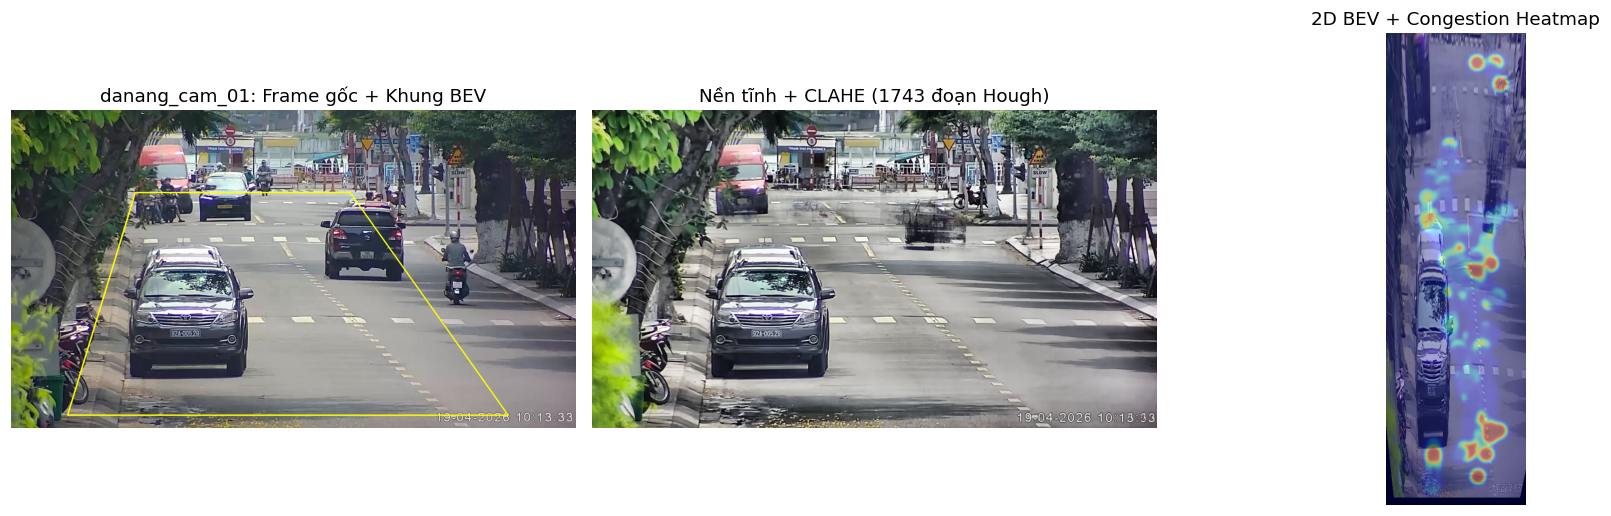

clips/LF_ZmCAo38w_C002.mp4: reconstructing file:   0%|          |  0.00B /  105MB            

clips/LF_ZmCAo38w_C002.mp4: downloading bytes:           |  0.00B            


>>> [2/3] Đang xử lý LF_ZmCAo38w_C002.mp4 (danang_cam_02) ...
  -> Đã xuất 2 video MP4: danang_cam_02_detected.mp4 & danang_cam_02_bev.mp4 (450 frames)


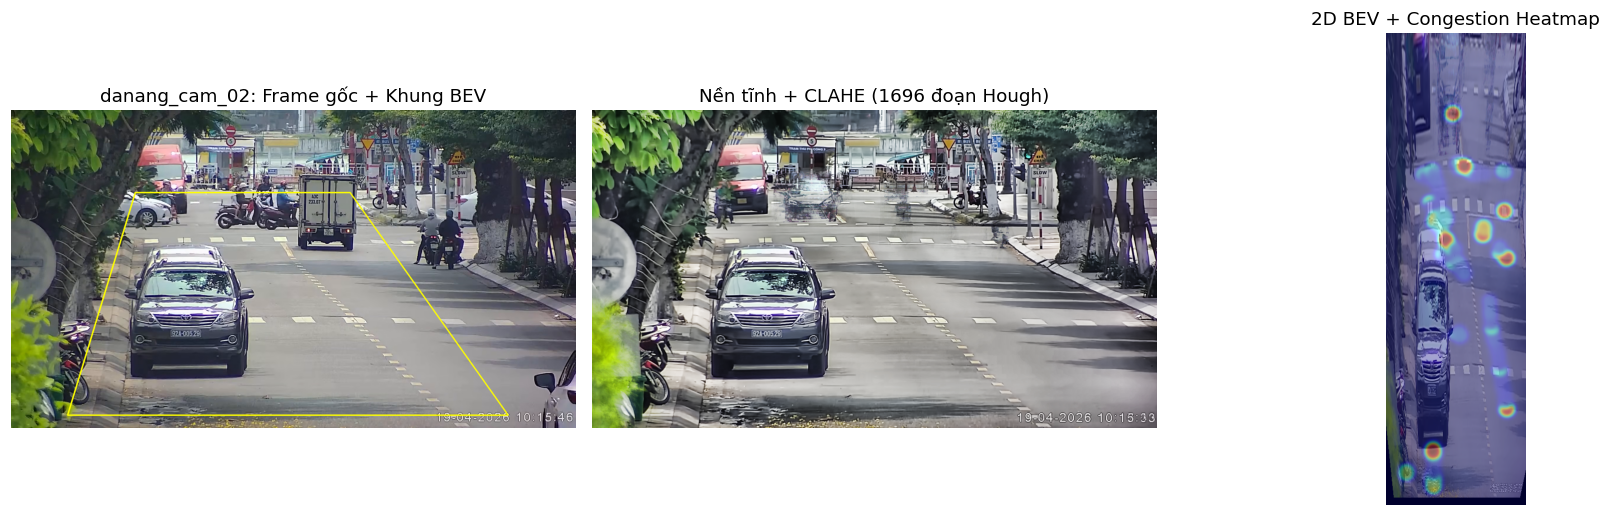

clips/LF_ZmCAo38w_C003.mp4: reconstructing file:   0%|          |  0.00B /  128MB            

clips/LF_ZmCAo38w_C003.mp4: downloading bytes:           |  0.00B            


>>> [3/3] Đang xử lý LF_ZmCAo38w_C003.mp4 (danang_cam_03) ...
  -> Đã xuất 2 video MP4: danang_cam_03_detected.mp4 & danang_cam_03_bev.mp4 (450 frames)


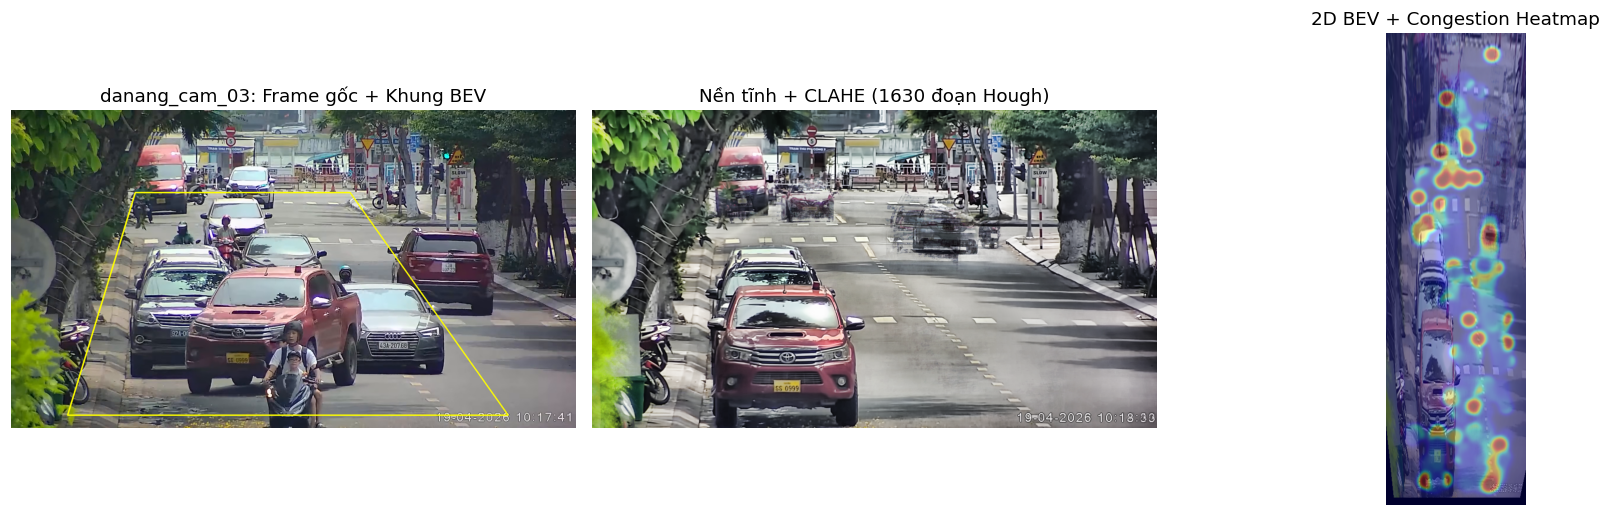


=== BẢNG TỔNG HỢP FULL-PIPELINE (CCTV ĐÀ NẴNG) ===


,Camera,Video,FPS,Hough_Segments,Detections,Counted_Vehicles,All_Mean_kmh,Moving_Mean_kmh,Max_Speed_kmh,Lane_Violations,THW_Alerts
0,danang_cam_01,LF_ZmCAo38w_C001.mp4,30.0,1743,3828,4,6.81,10.26,15.59,6,31
1,danang_cam_02,LF_ZmCAo38w_C002.mp4,30.0,1696,2744,3,5.04,9.10,12.49,2,0
2,danang_cam_03,LF_ZmCAo38w_C003.mp4,30.0,1630,4179,3,7.59,12.19,19.38,10,14


In [7]:
# === [5] Tải 3 video từ HuggingFace (nhthau/CCTV-giao-thong-da-nang) & Chạy Full Pipeline ===
from huggingface_hub import HfApi, hf_hub_download

def get_hf_token():
    try:
        from google.colab import userdata
        tok = userdata.get("HuggingFace")
        if tok:
            return tok.strip()
    except Exception:
        pass
    return os.environ.get("HF_TOKEN") or os.environ.get("HUGGINGFACE_TOKEN")

HF_REPO_ID = "nhthau/CCTV-giao-thong-da-nang"
hf_token = get_hf_token()
assert hf_token, "Không tìm thấy Colab Secret tên 'HuggingFace'! Hãy bật quyền truy cập Secret ở thanh bên trái Colab."

api = HfApi(token=hf_token)
repo_files = api.list_repo_files(repo_id=HF_REPO_ID, repo_type="dataset", token=hf_token)
mp4_files = sorted([f for f in repo_files if f.lower().endswith(".mp4")])[:3]
print(f"Tìm thấy {len([f for f in repo_files if f.lower().endswith('.mp4')])} video .mp4. Đang tải {len(mp4_files)} video đầu tiên:")
for f in mp4_files:
    print(" -", f)

active_model = model_vn if model_vn is not None else model_coco
active_is_coco = model_vn is None
print(f"Mô hình sử dụng cho Đà Nẵng: {'COCO yolo26s.pt (fallback)' if active_is_coco else VN_WEIGHTS_PATH.name}")

danang_summary = []

for idx, rel_path in enumerate(mp4_files, 1):
    local_vid = Path(hf_hub_download(
        repo_id=HF_REPO_ID, filename=rel_path, repo_type="dataset",
        token=hf_token, local_dir=str(DANANG_DIR)
    ))
    cam_id = f"danang_cam_{idx:02d}"
    print(f"\n>>> [{idx}/{len(mp4_files)}] Đang xử lý {local_vid.name} ({cam_id}) ...")

    crowded, bg_img, vinfo = compute_temporal_median_bg(local_vid, num_samples=60)
    undist, clahe_img = undistort_and_clahe(bg_img)
    # Góc cam Đà Nẵng (LF_ZmCAo38w) là đường 2 làn (~7m) + đoạn đường dài ~45m từ ngã tư tới mép dưới
    dn_cfg = build_bev_calibration(
        vinfo["width"], vinfo["height"],
        lane_width_m=3.5, road_len_m=45.0,
        src_trapezoid_norm=[[0.22, 0.26], [0.60, 0.26], [0.88, 0.96], [0.10, 0.96]]
    )

    _, _, hough_lines = detect_lanes_hls_canny_hough(clahe_img, dn_cfg["reliable_zone_uv"])
    n_hough = 0 if hough_lines is None else len(hough_lines)

    records, fps_dn = run_tracker_on_video(active_model, local_vid, cam_id, is_coco=active_is_coco, max_frames=900)
    res_dn = run_bev_analytics(records, dn_cfg, fps_dn)
    sdf = res_dn["speed_df"]

    # Xuất JSONL chuẩn Data Contract & Render 2 video MP4 (Camera nhận diện + BEV 2D)
    jsonl_out = OUT_DIR / f"tracks_{cam_id}.jsonl"
    with open(jsonl_out, "w", encoding="utf-8") as fj:
        for r in records:
            fj.write(json.dumps(r) + "\n")
    render_camera_and_bev_videos(local_vid, dn_cfg, res_dn, OUT_DIR, cam_id, max_frames=450)

    # Vẽ trực quan hóa 3 khung: Gốc (kèm khung hình thang hiệu chuẩn) + Nền tách xe + BEV Heatmap
    crowded_vis = crowded.copy()
    cv2.polylines(crowded_vis, [dn_cfg["reliable_zone_uv"].astype(np.int32)], True, (0, 255, 255), 3)
    bev_bg = cv2.warpPerspective(undist, dn_cfg["H_px"], (dn_cfg["bev_img_w"], dn_cfg["bev_img_h"]))
    hm = res_dn["heatmap_bev"]
    hm_norm = np.uint8(255 * hm / max(1e-6, float(hm.max())))
    hm_color = cv2.applyColorMap(hm_norm, cv2.COLORMAP_JET)
    bev_overlay = cv2.addWeighted(bev_bg, 0.65, hm_color, 0.35, 0)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    axes[0].imshow(cv2.cvtColor(crowded_vis, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"{cam_id}: Frame gốc + Khung BEV")
    axes[1].imshow(cv2.cvtColor(clahe_img, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f"Nền tĩnh + CLAHE ({n_hough} đoạn Hough)")
    axes[2].imshow(cv2.cvtColor(bev_overlay, cv2.COLOR_BGR2RGB))
    axes[2].set_title("2D BEV + Congestion Heatmap")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    fig_path = OUT_DIR / f"summary_{cam_id}.png"
    plt.savefig(fig_path, dpi=120)
    plt.show()

    moving_sdf = sdf[sdf["ema_kmh"] >= 5.0] if len(sdf) else sdf
    danang_summary.append({
        "Camera": cam_id,
        "Video": local_vid.name,
        "FPS": round(fps_dn, 1),
        "Hough_Segments": n_hough,
        "Detections": len(records),
        "Counted_Vehicles": res_dn["total_counted"],
        "All_Mean_kmh": round(float(sdf["ema_kmh"].mean()), 2) if len(sdf) else 0.0,
        "Moving_Mean_kmh": round(float(moving_sdf["ema_kmh"].mean()), 2) if len(moving_sdf) else 0.0,
        "Max_Speed_kmh": round(float(sdf["ema_kmh"].quantile(0.95)), 2) if len(sdf) else 0.0,
        "Lane_Violations": res_dn["lane_violations"],
        "THW_Alerts": res_dn["thw_alerts"],
    })

dn_df = pd.DataFrame(danang_summary)
print("\n=== BẢNG TỔNG HỢP FULL-PIPELINE (CCTV ĐÀ NẴNG) ===")
display(dn_df)
dn_df.to_csv(OUT_DIR / "danang_benchmark_summary.csv", index=False)

In [9]:
# === [6] Thống kê Toàn diện & Nén Toàn bộ Kết quả (.zip) Tải về Máy ===
print("=================================================================")
print("        TỔNG KẾT TOÀN BỘ KẾT QUẢ BENCHMARK FULL-PIPELINE         ")
print("=================================================================")

bench_csv = OUT_DIR / "multi_dataset_benchmark.csv"
dn_csv = OUT_DIR / "danang_benchmark_summary.csv"

df_bench_final = pd.read_csv(bench_csv) if bench_csv.exists() else (all_bench_df if "all_bench_df" in globals() else pd.DataFrame())
df_dn_final = pd.read_csv(dn_csv) if dn_csv.exists() else (dn_df if "dn_df" in globals() else pd.DataFrame())

report_lines = ["# BÁO CÁO TỔNG HỢP KẾT QUẢ FULL-PIPELINE (NGƯỜI A + NGƯỜI B)\n"]

if len(df_bench_final):
    print("\n[1] BẢNG ĐỐI CHỨNG TỐC ĐỘ THỰC ĐA BỘ DỮ LIỆU (COCO vs NGƯỜI A):")
    display(df_bench_final)
    report_lines.append("## 1. Bảng Đối chứng Tốc độ Thực Đa Bộ Dữ liệu (Luvizon, AICC22, VNTraffic)\n")
    report_lines.append(df_bench_final.to_markdown(index=False) + "\n\n")

    # Tính MAE trung bình & Độ giảm nhiễu theo từng Model
    df_valid_mae = df_bench_final[pd.to_numeric(df_bench_final["MAE_Error_kmh"], errors="coerce").notna()].copy()
    df_valid_mae["MAE_Error_kmh"] = df_valid_mae["MAE_Error_kmh"].astype(float)
    model_agg = df_bench_final.groupby("Model").agg(
        Datasets_Count=("Dataset", "count"),
        Total_Tracks=("Tracks", "sum"),
        Total_Counted=("Counted_Vehicles", "sum"),
        Mean_Raw_Std_kmh=("Raw_Std_kmh", "mean"),
        Mean_EMA_Std_kmh=("EMA_Std_kmh", "mean"),
    ).reset_index()
    if len(df_valid_mae):
        mae_by_m = df_valid_mae.groupby("Model")["MAE_Error_kmh"].mean().reset_index().rename(columns={"MAE_Error_kmh": "Mean_MAE_kmh"})
        model_agg = model_agg.merge(mae_by_m, on="Model", how="left")
    model_agg["Noise_Reduction_%"] = ((1.0 - model_agg["Mean_EMA_Std_kmh"] / model_agg["Mean_Raw_Std_kmh"].clip(lower=1e-4)) * 100.0).round(1)
    model_agg = model_agg.round(2)
    model_agg.to_csv(OUT_DIR / "model_comparison_summary.csv", index=False)

    print("\n[2] THỐNG KÊ TRUNG BÌNH THEO MÔ HÌNH (MAE & TỶ LỆ GIẢM NHIỄU TỐC ĐỘ):")
    display(model_agg)
    report_lines.append("## 2. Thống kê Trung bình theo Mô hình\n")
    report_lines.append(model_agg.to_markdown(index=False) + "\n\n")

if len(df_dn_final):
    print("\n[3] BẢNG KẾT QUẢ FULL-PIPELINE TRÊN 3 CAMERA CCTV ĐÀ NẴNG:")
    display(df_dn_final)
    report_lines.append("## 3. Bảng Kết quả Full-Pipeline trên 3 Camera CCTV Đà Nẵng\n")
    report_lines.append(df_dn_final.to_markdown(index=False) + "\n\n")

# Ghi file báo cáo Markdown tổng hợp
report_md_path = OUT_DIR / "FINAL_REPORT_SUMMARY.md"
report_md_path.write_text("".join(report_lines), encoding="utf-8")

# Liệt kê tất cả các tệp kết quả đã xuất trong OUT_DIR
out_files = sorted([p for p in OUT_DIR.rglob("*") if p.is_file()])
files_table = pd.DataFrame([{
    "File_Name": p.name,
    "Type": p.suffix.lower(),
    "Size_MB": round(p.stat().st_size / (1024 * 1024), 2),
    "Path": str(p),
} for p in out_files])
print(f"\n[4] DANH SÁCH {len(files_table)} FILE KẾT QUẢ ĐÃ XUẤT (CSV, MD, PNG, JSONL, MP4):")
display(files_table)

# Nén toàn bộ thư mục OUT_DIR thành 1 file .zip để tải về máy
zip_base = Path("/content/Final_FullPipeline_Results")
zip_file = Path("/content/Final_FullPipeline_Results.zip")
if zip_file.exists():
    zip_file.unlink()
shutil.make_archive(str(zip_base), "zip", str(OUT_DIR))
print(f"\n>>> ĐÃ NÉN TOÀN BỘ KẾT QUẢ: {zip_file} ({zip_file.stat().st_size / (1024 * 1024):.2f} MB)")

try:
    from google.colab import files
    files.download(str(zip_file))
except Exception as e:
    print("Bạn có thể tải trực tiếp file /content/Final_FullPipeline_Results.zip ở thanh Files bên trái Colab.", e)

        TỔNG KẾT TOÀN BỘ KẾT QUẢ BENCHMARK FULL-PIPELINE         

[1] BẢNG ĐỐI CHỨNG TỐC ĐỘ THỰC ĐA BỘ DỮ LIỆU (COCO vs NGƯỜI A):


,Dataset,Video,Model,Tracks,GT_Moving_kmh,Pred_Moving_kmh,MAE_Error_kmh,Raw_Std_kmh,EMA_Std_kmh,Counted_Vehicles
0,Luvizon (subset01_video01),luvizon_subset01_video01.mp4,yolo26s.pt (COCO: car/bus/truck),8,44.58,117.11,72.53,24.83,29.05,6
1,Luvizon (subset01_video01),luvizon_subset01_video01.mp4,yolo26_vn_finetuned.pt (Người A),15,44.58,113.61,69.03,46.24,33.62,10
2,Luvizon (subset01_video02),luvizon_subset01_video02.mp4,yolo26s.pt (COCO: car/bus/truck),10,46.40,56.27,9.87,62.25,43.87,3
3,Luvizon (subset01_video02),luvizon_subset01_video02.mp4,yolo26_vn_finetuned.pt (Người A),19,46.40,54.51,8.11,65.60,43.46,6
4,Luvizon (subset01_video03),luvizon_subset01_video03.mp4,yolo26s.pt (COCO: car/bus/truck),14,42.73,112.55,69.82,30.72,30.13,6
5,Luvizon (subset01_video03),luvizon_subset01_video03.mp4,yolo26_vn_finetuned.pt (Người A),18,42.73,114.72,71.99,43.01,29.66,11
6,AICC22-Custom (Human GT),AICC22-Custom_Original-video.mp4,yolo26s.pt (COCO: car/bus/truck),20,13.54,13.41,0.14,12.42,8.59,2
7,AICC22-Custom (Human GT),AICC22-Custom_Original-video.mp4,yolo26_vn_finetuned.pt (Người A),17,13.54,13.39,0.15,12.30,8.66,2
8,VNTraffic Hà Nội (Human GT),VNTraffic_Original-video.mp4,yolo26s.pt (COCO: car/bus/truck),40,7.21,6.66,0.56,4.07,2.24,0
9,VNTraffic Hà Nội (Human GT),VNTraffic_Original-video.mp4,yolo26_vn_finetuned.pt (Người A),66,7.21,7.28,0.07,6.89,2.71,0



[2] THỐNG KÊ TRUNG BÌNH THEO MÔ HÌNH (MAE & TỶ LỆ GIẢM NHIỄU TỐC ĐỘ):


,Model,Datasets_Count,Total_Tracks,Total_Counted,Mean_Raw_Std_kmh,Mean_EMA_Std_kmh,Mean_MAE_kmh,Noise_Reduction_%
0,yolo26_vn_finetuned.pt (Người A),5,135,29,34.81,23.62,29.87,32.1
1,yolo26s.pt (COCO: car/bus/truck),5,92,17,26.86,22.78,30.58,15.2



[3] BẢNG KẾT QUẢ FULL-PIPELINE TRÊN 3 CAMERA CCTV ĐÀ NẴNG:


,Camera,Video,FPS,Hough_Segments,Detections,Counted_Vehicles,All_Mean_kmh,Moving_Mean_kmh,Max_Speed_kmh,Lane_Violations,THW_Alerts
0,danang_cam_01,LF_ZmCAo38w_C001.mp4,30.0,1743,3828,4,6.81,10.26,15.59,6,31
1,danang_cam_02,LF_ZmCAo38w_C002.mp4,30.0,1696,2744,3,5.04,9.10,12.49,2,0
2,danang_cam_03,LF_ZmCAo38w_C003.mp4,30.0,1630,4179,3,7.59,12.19,19.38,10,14



[4] DANH SÁCH 16 FILE KẾT QUẢ ĐÃ XUẤT (CSV, MD, PNG, JSONL, MP4):


,File_Name,Type,Size_MB,Path
0,FINAL_REPORT_SUMMARY.md,.md,0.00,/content/final_pipeline/outputs/FINAL_REPORT_S...
1,danang_benchmark_summary.csv,.csv,0.00,/content/final_pipeline/outputs/danang_benchma...
2,danang_cam_01_bev.mp4,.mp4,4.67,/content/final_pipeline/outputs/danang_cam_01_...
3,danang_cam_01_detected.mp4,.mp4,23.96,/content/final_pipeline/outputs/danang_cam_01_...
4,danang_cam_02_bev.mp4,.mp4,4.40,/content/final_pipeline/outputs/danang_cam_02_...
5,danang_cam_02_detected.mp4,.mp4,24.36,/content/final_pipeline/outputs/danang_cam_02_...
6,danang_cam_03_bev.mp4,.mp4,10.55,/content/final_pipeline/outputs/danang_cam_03_...
7,danang_cam_03_detected.mp4,.mp4,46.09,/content/final_pipeline/outputs/danang_cam_03_...
8,model_comparison_summary.csv,.csv,0.00,/content/final_pipeline/outputs/model_comparis...
9,multi_dataset_benchmark.csv,.csv,0.00,/content/final_pipeline/outputs/multi_dataset_...



>>> ĐÃ NÉN TOÀN BỘ KẾT QUẢ: /content/Final_FullPipeline_Results.zip (114.54 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>